# Detección de fraude en seguros con una SNN

Prueba de regularización con `carclaims.csv`. Los cambios de código están
marcados como **CAMBIO**: LayerNorm y Dropout en la capa oculta, y diagnóstico
de la actividad de salida durante la validación. Esta variante necesita
ejecutarse desde el principio; sus resultados aún no se han obtenido.


### 0. Configuración del Entorno y Dependencias
Preparamos el terreno importando las librerías necesarias. Eliminamos la generación de datos sintéticos para forzarnos a usar la base de datos real.

In [ ]:
!pip install snntorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight
import os
import snntorch as snn
from snntorch import surrogate

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo de ejecución: {device}')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 5.4 MB/s eta 0:00:00
Dispositivo de ejecución: cuda


### 1. Carga de Datos y EDA
Verificamos que el archivo original esté presente e inspeccionamos los datos para entender el entorno.

Cargando dataset real carclaims.csv...

--- Información del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice  

/tmp/ipykernel_1906/2277653802.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='FraudFound', palette='Set2')


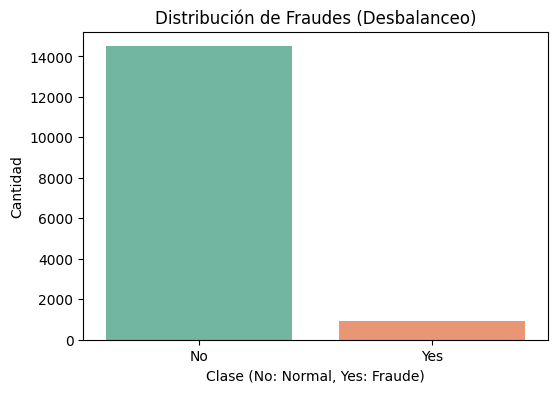

In [ ]:
file_path = 'carclaims.csv'
if not os.path.exists(file_path):
    raise FileNotFoundError(f"¡Error! No se encontró el archivo '{file_path}'. Asegúrate de subirlo a tu entorno de Colab.")

print("Cargando dataset real carclaims.csv...")
df = pd.read_csv(file_path)

print("\n--- Información del Dataset ---")
print(df.info())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='FraudFound', palette='Set2')
plt.title('Distribución de Fraudes (Desbalanceo)')
plt.xlabel('Clase (No: Normal, Yes: Fraude)')
plt.ylabel('Cantidad')
plt.show()


### 2. Preprocesamiento Seguro (Arreglo del Data Leakage)
Aquí es donde ocurrió el problema de fuga de datos. Al crear la variable objetivo `target`, la dejamos accidentalmente dentro del paquete de datos `X` que la red usa para aprender. Ahora, **eliminamos explícitamente tanto `FraudFound` como `target` de las características de entrada**.

In [ ]:
df_processed = df.copy()

# Convertimos la variable objetivo a binaria
df_processed['target'] = df_processed['FraudFound'].map({'No': 0, 'Yes': 1})

# SOLUCIÓN AL DATA LEAKAGE:
# Nos aseguramoos de borrar tanto la columna de texto original como la nueva columna numérica.
# También borramos PolicyNumber para que la red no memorice pólizas individuales.
columns_to_drop = ['FraudFound', 'target']
if 'PolicyNumber' in df_processed.columns:
    columns_to_drop.append('PolicyNumber')

# Separamos Características (X) y Etiquetas (y) de forma limpia
X_raw = df_processed.drop(columns=columns_to_drop)
y = df_processed['target'].values

# One-Hot Encoding para las variables de texto (Mes, Marca de coche, etc.)
X_encoded = pd.get_dummies(X_raw, drop_first=True)
X = X_encoded.astype(np.float32).values

print(f"Forma de la matriz X (sin trampa): {X.shape}")


Forma de la matriz X (sin trampa): (15420, 123)


### 3. División de Datos y Escalado
Mantenemos la división estricta Train/Val/Test y el escalado posterior para que la red no vea el futuro.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

#scaler = StandardScaler()
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long)), batch_size=16, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long)), batch_size=16, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long)), batch_size=16, shuffle=False)


### 4. Arquitectura y compensación del desbalanceo

Se mantiene la arquitectura `123 → 16 → 2` del último adjunto y sus dos capas
LIF. **CAMBIO:** se normalizan las 16 corrientes de entrada a la capa oculta
con `LayerNorm(16)` y se aplica `Dropout(0.2)` antes de su neurona LIF.
Dropout se calcula una sola vez por muestra y forward, de modo que la misma
máscara se mantiene durante los 10 pasos de esa simulación. En evaluación
Dropout queda desactivado por `model.eval()`.

La salida sigue siendo binaria por paso temporal: se conserva la suma de
spikes como entrada a CrossEntropyLoss y como criterio de clasificación.
No se añade una sigmoide. Los pesos de clase se calculan de nuevo dentro
de cada fold y no garantizan por sí solos un buen recall de fraude.


In [ ]:
num_steps = 15
beta = 0.9
spike_grad = surrogate.fast_sigmoid()

class SNNDeepAnomalyDetector(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        p_dropout = 0.15

        # Primera capa oculta
        self.fc1 = nn.Linear(input_size, 128)
        self.norm1 = nn.LayerNorm(128)
        self.dropout1 = nn.Dropout(p=p_dropout)
        self.lif1 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
        )

        # Segunda capa oculta
        self.fc2 = nn.Linear(128, 64)
        self.norm2 = nn.LayerNorm(64)
        self.dropout2 = nn.Dropout(p=p_dropout)
        self.lif2 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
        )

        # Tercera capa oculta
        self.fc3 = nn.Linear(64, 32)
        self.norm3 = nn.LayerNorm(32)
        self.dropout3 = nn.Dropout(p=p_dropout)
        self.lif3 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
        )

        # Salida: Normal y Fraude
        self.fc4 = nn.Linear(32, 2)
        self.lif4 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
        )

    def forward(self, x):
        # Reiniciar las membranas para cada batch
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        mem3 = self.lif3.init_leaky()
        mem4 = self.lif4.init_leaky()

        spk4_rec = []

        # La entrada es estática: esta corriente se calcula una vez.
        # La máscara de dropout se conserva durante la simulación.
        cur1 = self.fc1(x)
        cur1 = self.norm1(cur1)
        cur1 = self.dropout1(cur1)

        # Una máscara por muestra y capa, fija en el tiempo.
        # En evaluación, Dropout devuelve unos sin modificarlos.
        mask2 = self.dropout2(
            x.new_ones((x.size(0), self.fc2.out_features))
        )
        mask3 = self.dropout3(
            x.new_ones((x.size(0), self.fc3.out_features))
        )

        for _ in range(num_steps):
            # Primera capa LIF
            spk1, mem1 = self.lif1(cur1, mem1)

            # Segunda capa LIF
            cur2 = self.fc2(spk1)
            cur2 = self.norm2(cur2)
            cur2 = cur2 * mask2
            spk2, mem2 = self.lif2(cur2, mem2)

            # Tercera capa LIF
            cur3 = self.fc3(spk2)
            cur3 = self.norm3(cur3)
            cur3 = cur3 * mask3
            spk3, mem3 = self.lif3(cur3, mem3)

            # Capa de salida
            cur4 = self.fc4(spk3)
            spk4, mem4 = self.lif4(cur4, mem4)

            spk4_rec.append(spk4)

        # Forma: [pasos temporales, batch, 2 clases]
        return torch.stack(spk4_rec, dim=0)

model = SNNDeepAnomalyDetector(input_size=X_train.shape[1]).to(device)

pesos = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
pesos_tensor = torch.tensor(pesos, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=pesos_tensor)
# Mismo optimizador e hiperparámetros que en la ANN final.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-2,
)
print(model)


SNNDeepAnomalyDetector(
  (fc1): Linear(in_features=123, out_features=128, bias=True)
  (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.15, inplace=False)
  (lif1): Leaky()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (dropout2): Dropout(p=0.15, inplace=False)
  (lif2): Leaky()
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (norm3): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (dropout3): Dropout(p=0.15, inplace=False)
  (lif3): Leaky()
  (fc4): Linear(in_features=32, out_features=2, bias=True)
  (lif4): Leaky()
)


### 5. Validación cruzada y monitorización

Se conservan los valores del último adjunto: **5 folds, 50 épocas, batch 32,
10 pasos temporales y reparto 75 % / 12,5 % / 12,5 %**. También se mantienen
AdamW (`lr=1e-4`, `weight_decay=1e-2`) y StepLR (`step_size=10`, `gamma=0.5`).
El scheduler se crea de nuevo para cada entrenamiento y avanza al terminar
cada época. Para el experimento final de 10 folds, cambiar `n_folds` a 10.
Para comparar con la ANN, ambas deben usar las mismas observaciones de
train/validación/test y el mismo protocolo de evaluación.

Cada fold crea su propio modelo, escalador y pesos de clase usando solo su
train. Las métricas se calculan con la última época; se mantiene el
entrenamiento completo, sin checkpoints ni parada anticipada. Después se
entrena un modelo nuevo con todo el train original y se usa el test una vez
fijadas las decisiones con entrenamiento y validación.

**CAMBIO:** además de F1 y recall, se registra AUC, la fracción de muestras
predichas como fraude, los empates entre los dos recuentos y las salidas sin
spikes. Empates y silencio también se miden específicamente sobre los
fraudes reales de validación. `argmax` resuelve un empate a favor de la clase
0 (Normal); por eso un recall muy bajo requiere revisar esta información.
Estas trazas permiten comprobar la hipótesis de una salida poco activa,
sin darla por demostrada de antemano. Todas estas fracciones van de 0 a 1;
el registro por época las muestra como porcentajes.

En los gráficos se añaden F1 y recall de validación. Con Dropout activo
durante el entrenamiento y desactivado durante la validación, acercar las
dos pérdidas no basta para demostrar una mejora: comparar también las
métricas de validación y su variación entre folds.

El adjunto de partida se interrumpió en el fold 3. Los dos folds completos
terminaban con F1 de 0,080 y 0,058, y recall de 0,051 y 0,036. No había
resultados de test ni una media completa de validación cruzada.


Fold 1/10 | Epoch [1/25] | Train Loss: 0.7323 | Val Loss: 0.6693 | F1: 0.000 | Recall: 0.000 | AUC: 0.570 | Fraude pred.: 0.0% | Empates en fraudes: 97.3% | Sin spikes en fraudes: 97.3% | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [2/25] | Train Loss: 0.6875 | Val Loss: 0.6475 | F1: 0.000 | Recall: 0.000 | AUC: 0.654 | Fraude pred.: 0.0% | Empates en fraudes: 94.6% | Sin spikes en fraudes: 94.6% | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [3/25] | Train Loss: 0.6531 | Val Loss: 0.6421 | F1: 0.000 | Recall: 0.000 | AUC: 0.663 | Fraude pred.: 0.0% | Empates en fraudes: 95.9% | Sin spikes en fraudes: 95.9% | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [4/25] | Train Loss: 0.6591 | Val Loss: 0.6336 | F1: 0.000 | Recall: 0.000 | AUC: 0.671 | Fraude pred.: 0.0% | Empates en fraudes: 95.9% | Sin spikes en fraudes: 95.9% | LR próxima época: 1.00e-04
Fold 1/10 | Epoch [5/25] | Train Loss: 0.6482 | Val Loss: 0.6280 | F1: 0.000 | Recall: 0.000 | AUC: 0.705 | Fraude pred.: 0.0% | Empates en 

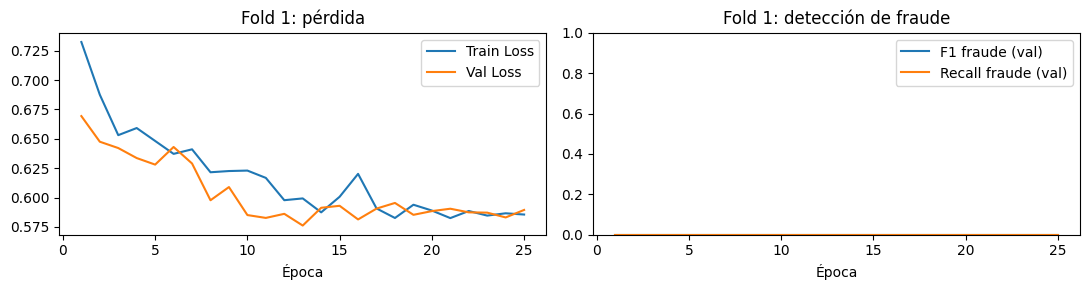

Fold 2/10 | Epoch [1/25] | Train Loss: 0.7242 | Val Loss: 0.6509 | F1: 0.000 | Recall: 0.000 | AUC: 0.610 | Fraude pred.: 0.0% | Empates en fraudes: 95.9% | Sin spikes en fraudes: 95.9% | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [2/25] | Train Loss: 0.6998 | Val Loss: 0.6238 | F1: 0.000 | Recall: 0.000 | AUC: 0.683 | Fraude pred.: 0.0% | Empates en fraudes: 93.2% | Sin spikes en fraudes: 93.2% | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [3/25] | Train Loss: 0.6690 | Val Loss: 0.6331 | F1: 0.000 | Recall: 0.000 | AUC: 0.713 | Fraude pred.: 0.0% | Empates en fraudes: 89.2% | Sin spikes en fraudes: 89.2% | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [4/25] | Train Loss: 0.6516 | Val Loss: 0.6392 | F1: 0.000 | Recall: 0.000 | AUC: 0.717 | Fraude pred.: 0.0% | Empates en fraudes: 90.5% | Sin spikes en fraudes: 90.5% | LR próxima época: 1.00e-04
Fold 2/10 | Epoch [5/25] | Train Loss: 0.6381 | Val Loss: 0.6600 | F1: 0.000 | Recall: 0.000 | AUC: 0.721 | Fraude pred.: 0.0% | Empates en 

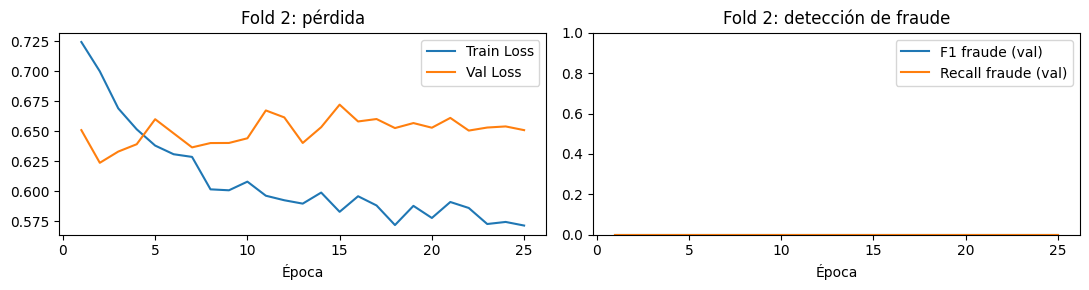

Fold 3/10 | Epoch [1/25] | Train Loss: 0.7506 | Val Loss: 0.6691 | F1: 0.000 | Recall: 0.000 | AUC: 0.586 | Fraude pred.: 0.0% | Empates en fraudes: 91.9% | Sin spikes en fraudes: 91.9% | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [2/25] | Train Loss: 0.6831 | Val Loss: 0.6559 | F1: 0.000 | Recall: 0.000 | AUC: 0.687 | Fraude pred.: 0.0% | Empates en fraudes: 87.8% | Sin spikes en fraudes: 87.8% | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [3/25] | Train Loss: 0.6717 | Val Loss: 0.6472 | F1: 0.000 | Recall: 0.000 | AUC: 0.692 | Fraude pred.: 0.0% | Empates en fraudes: 91.9% | Sin spikes en fraudes: 91.9% | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [4/25] | Train Loss: 0.6481 | Val Loss: 0.7305 | F1: 0.000 | Recall: 0.000 | AUC: 0.715 | Fraude pred.: 0.0% | Empates en fraudes: 73.0% | Sin spikes en fraudes: 73.0% | LR próxima época: 1.00e-04
Fold 3/10 | Epoch [5/25] | Train Loss: 0.6444 | Val Loss: 0.6744 | F1: 0.000 | Recall: 0.000 | AUC: 0.729 | Fraude pred.: 0.0% | Empates en 

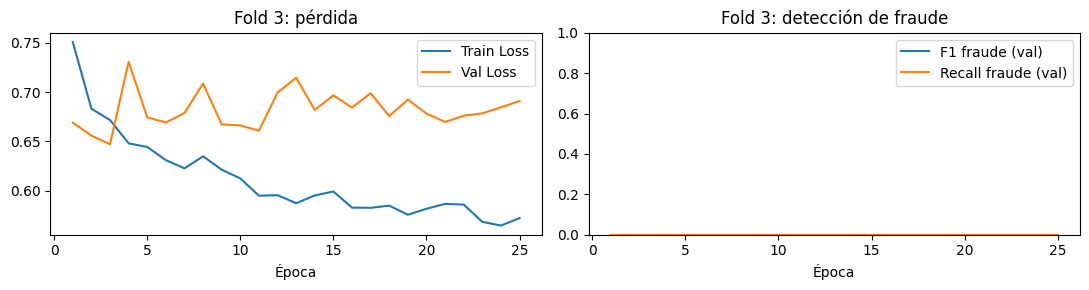

Fold 4/10 | Epoch [1/25] | Train Loss: 0.7246 | Val Loss: 0.6570 | F1: 0.000 | Recall: 0.000 | AUC: 0.613 | Fraude pred.: 0.0% | Empates en fraudes: 86.5% | Sin spikes en fraudes: 86.5% | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [2/25] | Train Loss: 0.6778 | Val Loss: 0.7134 | F1: 0.000 | Recall: 0.000 | AUC: 0.643 | Fraude pred.: 0.0% | Empates en fraudes: 68.9% | Sin spikes en fraudes: 68.9% | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [3/25] | Train Loss: 0.6663 | Val Loss: 0.6284 | F1: 0.000 | Recall: 0.000 | AUC: 0.687 | Fraude pred.: 0.0% | Empates en fraudes: 93.2% | Sin spikes en fraudes: 93.2% | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [4/25] | Train Loss: 0.6503 | Val Loss: 0.6732 | F1: 0.000 | Recall: 0.000 | AUC: 0.723 | Fraude pred.: 0.0% | Empates en fraudes: 74.3% | Sin spikes en fraudes: 74.3% | LR próxima época: 1.00e-04
Fold 4/10 | Epoch [5/25] | Train Loss: 0.6391 | Val Loss: 0.6506 | F1: 0.000 | Recall: 0.000 | AUC: 0.729 | Fraude pred.: 0.0% | Empates en 

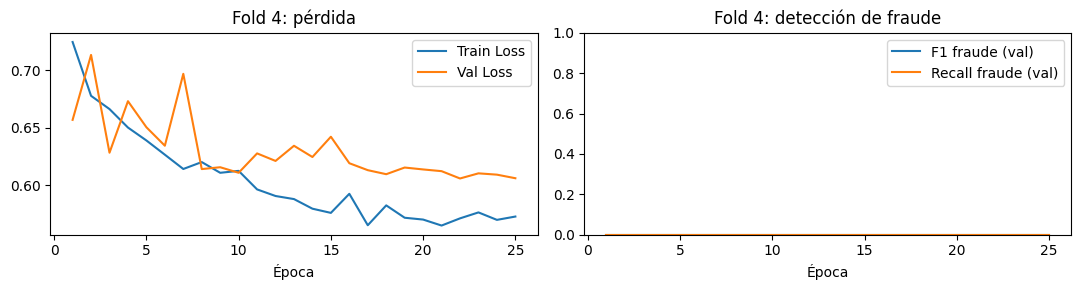

Fold 5/10 | Epoch [1/25] | Train Loss: 0.7301 | Val Loss: 0.6470 | F1: 0.000 | Recall: 0.000 | AUC: 0.634 | Fraude pred.: 0.0% | Empates en fraudes: 90.5% | Sin spikes en fraudes: 90.5% | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [2/25] | Train Loss: 0.6806 | Val Loss: 0.6919 | F1: 0.000 | Recall: 0.000 | AUC: 0.659 | Fraude pred.: 0.0% | Empates en fraudes: 77.0% | Sin spikes en fraudes: 77.0% | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [3/25] | Train Loss: 0.6763 | Val Loss: 0.6491 | F1: 0.000 | Recall: 0.000 | AUC: 0.675 | Fraude pred.: 0.0% | Empates en fraudes: 89.2% | Sin spikes en fraudes: 89.2% | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [4/25] | Train Loss: 0.6544 | Val Loss: 0.7135 | F1: 0.000 | Recall: 0.000 | AUC: 0.712 | Fraude pred.: 0.0% | Empates en fraudes: 70.3% | Sin spikes en fraudes: 70.3% | LR próxima época: 1.00e-04
Fold 5/10 | Epoch [5/25] | Train Loss: 0.6464 | Val Loss: 0.6356 | F1: 0.000 | Recall: 0.000 | AUC: 0.732 | Fraude pred.: 0.0% | Empates en 

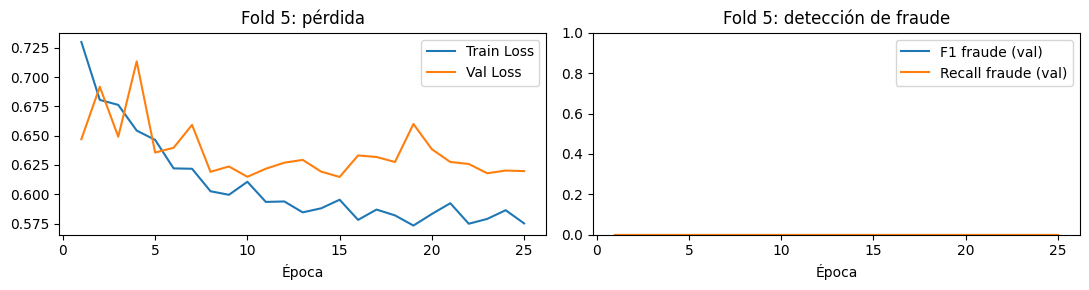

Fold 6/10 | Epoch [1/25] | Train Loss: 0.7391 | Val Loss: 0.6383 | F1: 0.000 | Recall: 0.000 | AUC: 0.638 | Fraude pred.: 0.0% | Empates en fraudes: 94.6% | Sin spikes en fraudes: 94.6% | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [2/25] | Train Loss: 0.6954 | Val Loss: 0.6200 | F1: 0.000 | Recall: 0.000 | AUC: 0.728 | Fraude pred.: 0.0% | Empates en fraudes: 86.5% | Sin spikes en fraudes: 86.5% | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [3/25] | Train Loss: 0.6594 | Val Loss: 0.5949 | F1: 0.000 | Recall: 0.000 | AUC: 0.728 | Fraude pred.: 0.0% | Empates en fraudes: 90.5% | Sin spikes en fraudes: 90.5% | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [4/25] | Train Loss: 0.6598 | Val Loss: 0.6383 | F1: 0.000 | Recall: 0.000 | AUC: 0.722 | Fraude pred.: 0.0% | Empates en fraudes: 83.8% | Sin spikes en fraudes: 83.8% | LR próxima época: 1.00e-04
Fold 6/10 | Epoch [5/25] | Train Loss: 0.6390 | Val Loss: 0.6322 | F1: 0.000 | Recall: 0.000 | AUC: 0.725 | Fraude pred.: 0.0% | Empates en 

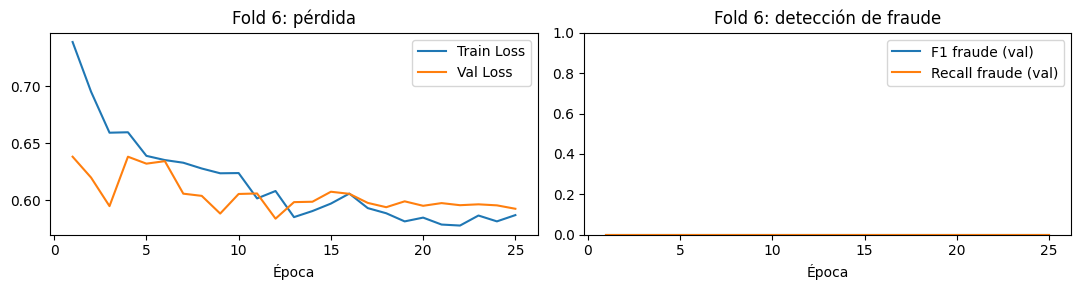

Fold 7/10 | Epoch [1/25] | Train Loss: 0.7474 | Val Loss: 0.6494 | F1: 0.000 | Recall: 0.000 | AUC: 0.600 | Fraude pred.: 0.0% | Empates en fraudes: 98.6% | Sin spikes en fraudes: 98.6% | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [2/25] | Train Loss: 0.6796 | Val Loss: 0.5905 | F1: 0.000 | Recall: 0.000 | AUC: 0.718 | Fraude pred.: 0.0% | Empates en fraudes: 87.7% | Sin spikes en fraudes: 87.7% | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [3/25] | Train Loss: 0.6839 | Val Loss: 0.6087 | F1: 0.000 | Recall: 0.000 | AUC: 0.665 | Fraude pred.: 0.0% | Empates en fraudes: 98.6% | Sin spikes en fraudes: 98.6% | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [4/25] | Train Loss: 0.6620 | Val Loss: 0.5788 | F1: 0.000 | Recall: 0.000 | AUC: 0.734 | Fraude pred.: 0.0% | Empates en fraudes: 86.3% | Sin spikes en fraudes: 86.3% | LR próxima época: 1.00e-04
Fold 7/10 | Epoch [5/25] | Train Loss: 0.6474 | Val Loss: 0.5554 | F1: 0.000 | Recall: 0.000 | AUC: 0.761 | Fraude pred.: 0.0% | Empates en 

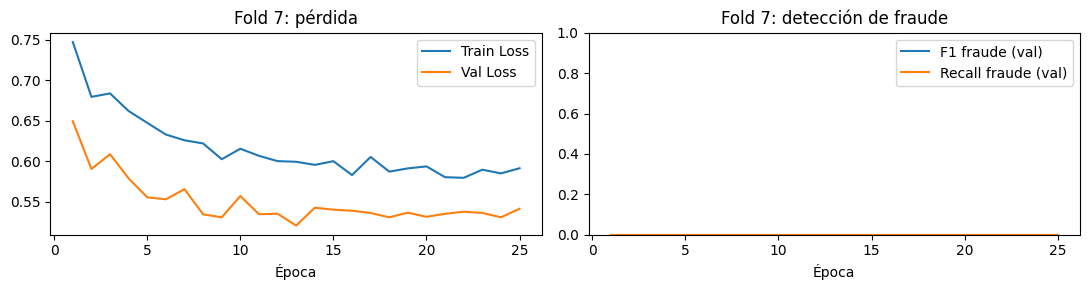

Fold 8/10 | Epoch [1/25] | Train Loss: 0.7533 | Val Loss: 0.6896 | F1: 0.000 | Recall: 0.000 | AUC: 0.633 | Fraude pred.: 0.0% | Empates en fraudes: 75.3% | Sin spikes en fraudes: 75.3% | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [2/25] | Train Loss: 0.6975 | Val Loss: 0.6787 | F1: 0.000 | Recall: 0.000 | AUC: 0.660 | Fraude pred.: 0.0% | Empates en fraudes: 78.1% | Sin spikes en fraudes: 78.1% | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [3/25] | Train Loss: 0.6657 | Val Loss: 0.6626 | F1: 0.000 | Recall: 0.000 | AUC: 0.726 | Fraude pred.: 0.0% | Empates en fraudes: 76.7% | Sin spikes en fraudes: 76.7% | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [4/25] | Train Loss: 0.6527 | Val Loss: 0.6159 | F1: 0.000 | Recall: 0.000 | AUC: 0.730 | Fraude pred.: 0.0% | Empates en fraudes: 87.7% | Sin spikes en fraudes: 87.7% | LR próxima época: 1.00e-04
Fold 8/10 | Epoch [5/25] | Train Loss: 0.6430 | Val Loss: 0.6281 | F1: 0.000 | Recall: 0.000 | AUC: 0.749 | Fraude pred.: 0.0% | Empates en 

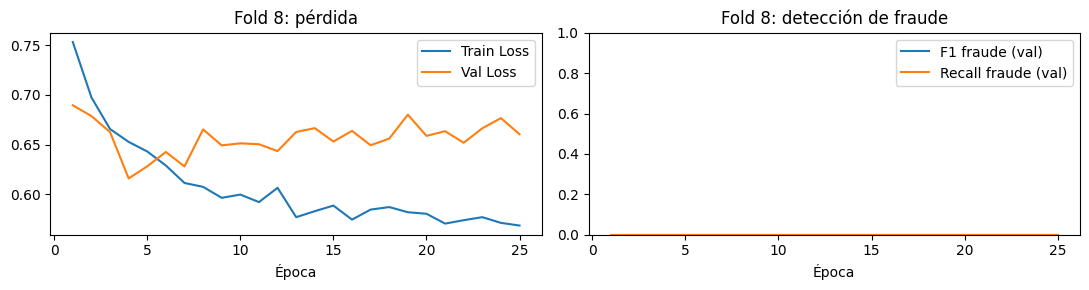

Fold 9/10 | Epoch [1/25] | Train Loss: 0.7240 | Val Loss: 0.6318 | F1: 0.000 | Recall: 0.000 | AUC: 0.656 | Fraude pred.: 0.0% | Empates en fraudes: 93.2% | Sin spikes en fraudes: 93.2% | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [2/25] | Train Loss: 0.6891 | Val Loss: 0.6235 | F1: 0.000 | Recall: 0.000 | AUC: 0.678 | Fraude pred.: 0.0% | Empates en fraudes: 91.9% | Sin spikes en fraudes: 91.9% | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [3/25] | Train Loss: 0.6761 | Val Loss: 0.6193 | F1: 0.000 | Recall: 0.000 | AUC: 0.667 | Fraude pred.: 0.0% | Empates en fraudes: 91.9% | Sin spikes en fraudes: 91.9% | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [4/25] | Train Loss: 0.6752 | Val Loss: 0.6133 | F1: 0.000 | Recall: 0.000 | AUC: 0.662 | Fraude pred.: 0.0% | Empates en fraudes: 93.2% | Sin spikes en fraudes: 93.2% | LR próxima época: 1.00e-04
Fold 9/10 | Epoch [5/25] | Train Loss: 0.6414 | Val Loss: 0.6242 | F1: 0.000 | Recall: 0.000 | AUC: 0.717 | Fraude pred.: 0.0% | Empates en 

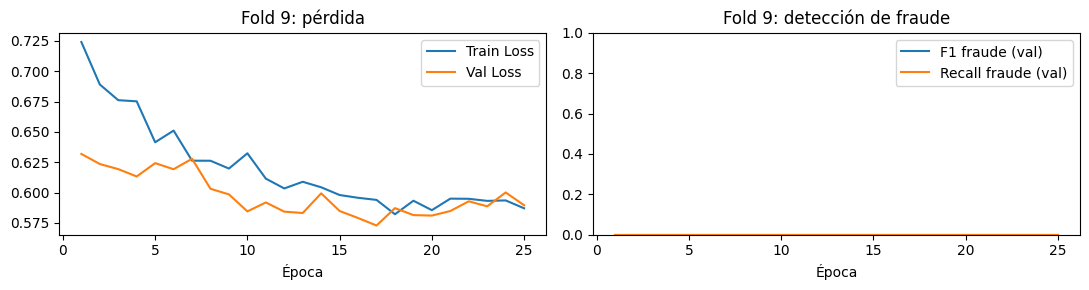

Fold 10/10 | Epoch [1/25] | Train Loss: 0.7399 | Val Loss: 0.6953 | F1: 0.000 | Recall: 0.000 | AUC: 0.585 | Fraude pred.: 0.0% | Empates en fraudes: 81.1% | Sin spikes en fraudes: 81.1% | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [2/25] | Train Loss: 0.6817 | Val Loss: 0.7166 | F1: 0.000 | Recall: 0.000 | AUC: 0.636 | Fraude pred.: 0.0% | Empates en fraudes: 74.3% | Sin spikes en fraudes: 74.3% | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [3/25] | Train Loss: 0.6723 | Val Loss: 0.6506 | F1: 0.000 | Recall: 0.000 | AUC: 0.661 | Fraude pred.: 0.0% | Empates en fraudes: 85.1% | Sin spikes en fraudes: 85.1% | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [4/25] | Train Loss: 0.6571 | Val Loss: 0.6024 | F1: 0.000 | Recall: 0.000 | AUC: 0.705 | Fraude pred.: 0.0% | Empates en fraudes: 89.2% | Sin spikes en fraudes: 89.2% | LR próxima época: 1.00e-04
Fold 10/10 | Epoch [5/25] | Train Loss: 0.6502 | Val Loss: 0.5971 | F1: 0.000 | Recall: 0.000 | AUC: 0.714 | Fraude pred.: 0.0% | Empate

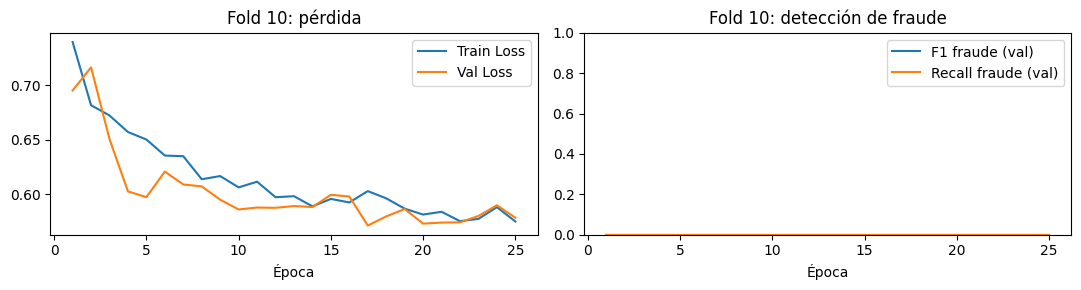


Validación cruzada: métricas de la última época


,Precision,Recall,F1,AUC
Fold,,,,
1,0.0,0.0,0.0,0.7808
2,0.0,0.0,0.0,0.7574
3,0.0,0.0,0.0,0.7487
4,0.0,0.0,0.0,0.7531
5,0.0,0.0,0.0,0.7732
6,0.0,0.0,0.0,0.7742
7,0.0,0.0,0.0,0.7772
8,0.0,0.0,0.0,0.7501
9,0.0,0.0,0.0,0.7801



Media y desviación entre folds


,Precision,Recall,F1,AUC
mean,0.0,0.0,0.0,0.7664
std,0.0,0.0,0.0,0.0127



Entrenamiento final con el train original
Final | Epoch [1/25] | Train Loss: 0.7240 | Val Loss: 0.6290 | F1: 0.000 | Recall: 0.000 | AUC: 0.669 | Fraude pred.: 0.0% | Empates en fraudes: 91.4% | Sin spikes en fraudes: 91.4% | LR próxima época: 1.00e-04
Final | Epoch [2/25] | Train Loss: 0.6802 | Val Loss: 0.6194 | F1: 0.000 | Recall: 0.000 | AUC: 0.679 | Fraude pred.: 0.0% | Empates en fraudes: 92.5% | Sin spikes en fraudes: 92.5% | LR próxima época: 1.00e-04
Final | Epoch [3/25] | Train Loss: 0.6753 | Val Loss: 0.7180 | F1: 0.000 | Recall: 0.000 | AUC: 0.731 | Fraude pred.: 0.0% | Empates en fraudes: 67.7% | Sin spikes en fraudes: 67.7% | LR próxima época: 1.00e-04
Final | Epoch [4/25] | Train Loss: 0.6574 | Val Loss: 0.6103 | F1: 0.000 | Recall: 0.000 | AUC: 0.742 | Fraude pred.: 0.0% | Empates en fraudes: 90.3% | Sin spikes en fraudes: 90.3% | LR próxima época: 1.00e-04
Final | Epoch [5/25] | Train Loss: 0.6261 | Val Loss: 0.6231 | F1: 0.000 | Recall: 0.000 | AUC: 0.755 | Fraude pr

In [6]:
# SNN: conservar el protocolo del último adjunto y añadir diagnóstico.
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score, precision_score

epochs = 25
n_folds = 10  # Usar 10 cuando se ejecute el experimento final de 10 folds.

# NUEVO: reutilizar la arquitectura y el optimizador ya definidos.
ClaseModelo = type(model)
ClaseOptimizador = type(optimizer)
opciones_optimizer = optimizer.defaults.copy()
opciones_optimizer.pop("decoupled_weight_decay", None)

batch_size = train_loader.batch_size


def reiniciar_modelo(y_entrenamiento):
    """Crear un modelo desde cero y calcular pesos solo con su train."""
    torch.manual_seed(42)

    nuevo_modelo = ClaseModelo(
        input_size=X_train.shape[1]
    ).to(device)

    pesos = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_entrenamiento,
    )
    pesos = torch.tensor(
        pesos, dtype=torch.float32, device=device
    )

    nuevo_criterion = nn.CrossEntropyLoss(weight=pesos)
    nuevo_optimizer = ClaseOptimizador(
        nuevo_modelo.parameters(), **opciones_optimizer
    )

    return nuevo_modelo, nuevo_optimizer, nuevo_criterion


def entrenar(model, optimizer, criterion,
             train_loader, val_loader, etiqueta):

    # Bucle original dentro de una función para poder repetirlo.
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_f1": [],
        "val_recall": [],
        # CAMBIO: trazas para separar clasificación y actividad de salida.
        "val_auc": [],
        "val_pred_fraud": [],
        "val_ties": [],
        "val_silent": [],
        "val_ties_fraud": [],
        "val_silent_fraud": [],
    }
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=5,
        gamma=0.5,
        )
    for epoch in range(epochs):
        model.train()
        train_loss, train_weight = 0.0, 0.0

        for data, target in train_loader:
            data, target = data.to(device), target.to(device)

            optimizer.zero_grad()
            output = model(data)

            # SNN: sumar los spikes de todos los pasos antes de aplicar la pérdida.
            if output.ndim == 3:
                output = output.sum(dim=0)

            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            # Acumulación correcta de la pérdida ponderada.
            peso_batch = criterion.weight[target].sum().item()
            train_loss += loss.item() * peso_batch
            train_weight += peso_batch

        model.eval()
        val_loss, val_weight = 0.0, 0.0
        y_true, y_pred, y_probs = [], [], []
        # CAMBIO: contar empates y silencio en validación, también en fraudes.
        n_val = n_fraud = n_pred_fraud = 0
        n_ties = n_silent = n_ties_fraud = n_silent_fraud = 0

        with torch.no_grad():
            for data, target in val_loader:
                data, target = data.to(device), target.to(device)
                output = model(data)

                if output.ndim == 3:
                    output = output.sum(dim=0)

                loss = criterion(output, target)

                peso_batch = criterion.weight[target].sum().item()
                val_loss += loss.item() * peso_batch
                val_weight += peso_batch

                # CAMBIO: diagnosticar el recuento antes de convertirlo en clases.
                preds = output.argmax(dim=1)
                ties = output[:, 0] == output[:, 1]
                silent = (output == 0).all(dim=1)
                fraud = target == 1
                n_val += target.numel()
                n_fraud += fraud.sum().item()
                n_pred_fraud += (preds == 1).sum().item()
                n_ties += ties.sum().item()
                n_silent += silent.sum().item()
                n_ties_fraud += (ties & fraud).sum().item()
                n_silent_fraud += (silent & fraud).sum().item()

                y_true.extend(target.cpu().numpy())
                y_pred.extend(preds.cpu().numpy())
                y_probs.extend(
                    torch.softmax(output.double(), dim=1)[:, 1]
                    .cpu().numpy()
                )

        avg_train_loss = train_loss / train_weight
        avg_val_loss = val_loss / val_weight
        #avanzamos el scheduler
        scheduler.step()

        f1 = f1_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        auc = roc_auc_score(y_true, y_probs)
        pred_fraud = n_pred_fraud / n_val
        ties_fraud = n_ties_fraud / max(n_fraud, 1)
        silent_fraud = n_silent_fraud / max(n_fraud, 1)

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_f1"].append(f1)
        history["val_recall"].append(recall)
        history["val_auc"].append(auc)
        history["val_pred_fraud"].append(pred_fraud)
        history["val_ties"].append(n_ties / n_val)
        history["val_silent"].append(n_silent / n_val)
        history["val_ties_fraud"].append(ties_fraud)
        history["val_silent_fraud"].append(silent_fraud)

        print(
            f"{etiqueta} | Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"F1: {f1:.3f} | Recall: {recall:.3f} | AUC: {auc:.3f}"
            f" | Fraude pred.: {pred_fraud:.1%}"
            f" | Empates en fraudes: {ties_fraud:.1%}"
            f" | Sin spikes en fraudes: {silent_fraud:.1%}"
            f" | LR próxima época: {optimizer.param_groups[0]['lr']:.2e}"
        )

    # Métricas correspondientes a la ÚLTIMA época.
    metricas = {
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall,
        "F1": f1,
        "AUC": roc_auc_score(y_true, y_probs),
    }

    return history, metricas


# NUEVO: recuperar los datos de train antes de su escalado.
# Cada fold tendrá un escalador ajustado solo con su propio train.
# El scaler original y el test_loader permanecen disponibles.
X_cv = scaler.inverse_transform(X_train)
y_cv = np.asarray(y_train)

cv = StratifiedKFold(
    n_splits=n_folds,
    shuffle=True,
    random_state=42,
)

histories_cv = {}
metricas_cv = []

for fold, (idx_train, idx_val) in enumerate(
    cv.split(X_cv, y_cv), start=1
):
    #scaler_fold = StandardScaler()
    scaler_fold = MinMaxScaler()
    Xtr = scaler_fold.fit_transform(X_cv[idx_train])
    Xva = scaler_fold.transform(X_cv[idx_val])

    train_loader_fold = DataLoader(
        TensorDataset(
            torch.tensor(Xtr, dtype=torch.float32),
            torch.tensor(y_cv[idx_train], dtype=torch.long),
        ),
        batch_size=batch_size,
        shuffle=True,
    )

    val_loader_fold = DataLoader(
        TensorDataset(
            torch.tensor(Xva, dtype=torch.float32),
            torch.tensor(y_cv[idx_val], dtype=torch.long),
        ),
        batch_size=batch_size,
        shuffle=False,
    )

    model_fold, optimizer_fold, criterion_fold = reiniciar_modelo(
        y_cv[idx_train]
    )

    history_fold, metricas_fold = entrenar(
        model_fold,
        optimizer_fold,
        criterion_fold,
        train_loader_fold,
        val_loader_fold,
        f"Fold {fold}/{n_folds}",
    )

    histories_cv[fold] = history_fold
    metricas_cv.append({"Fold": fold, **metricas_fold})

    # CAMBIO: mostrar detección de fraude junto a la pérdida.
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    epocas = range(1, epochs + 1)
    axes[0].plot(epocas, history_fold["train_loss"], label="Train Loss")
    axes[0].plot(epocas, history_fold["val_loss"], label="Val Loss")
    axes[0].set_title(f"Fold {fold}: pérdida")
    axes[0].set_xlabel("Época")
    axes[0].legend()
    axes[1].plot(epocas, history_fold["val_f1"], label="F1 fraude (val)")
    axes[1].plot(epocas, history_fold["val_recall"], label="Recall fraude (val)")
    axes[1].set_title(f"Fold {fold}: detección de fraude")
    axes[1].set_xlabel("Época")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

resultados_cv = pd.DataFrame(metricas_cv).set_index("Fold")

print("\nValidación cruzada: métricas de la última época")
display(resultados_cv.round(4))

print("\nMedia y desviación entre folds")
display(resultados_cv.agg(["mean", "std"]).round(4))


# NUEVO: entrenamiento final con TODO el train original.
# Deja model e history preparados para la celda de evaluación original.
print("\nEntrenamiento final con el train original")

model, optimizer, criterion = reiniciar_modelo(y_train)

history, metricas_finales_val = entrenar(
    model,
    optimizer,
    criterion,
    train_loader,
    val_loader,
    "Final",
)

## Seleccionar umbral que maximice f1-score de fraude

In [7]:
import numpy as np
import torch
from sklearn.metrics import precision_recall_curve


def seleccionar_umbral_f1(modelo, val_loader, dispositivo):
    modelo.eval()
    y_true, y_scores = [], []

    with torch.no_grad():
        for data, target in val_loader:
            output = modelo(data.to(dispositivo))

            # SNN: acumular spikes. ANN: conservar logits.
            if output.ndim == 3:
                output = output.sum(dim=0)

            scores = torch.softmax(
                output.double(), dim=1
            )[:, 1]

            y_true.extend(target.cpu().numpy())
            y_scores.extend(scores.cpu().numpy())

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_scores
    )

    # El último punto de la curva no tiene umbral asociado.
    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    )

    idx = int(np.argmax(f1))
    umbral = float(thresholds[idx])

    print(f"Umbral elegido: {umbral:.6f}")
    print(
        f"Selección en validación | F1: {f1[idx]:.4f} | "
        f"Precisión: {precision[idx]:.4f} | "
        f"Recall: {recall[idx]:.4f}"
    )

    return umbral


umbral = seleccionar_umbral_f1(model, val_loader, device)

Umbral elegido: 0.500000
Selección en validación | F1: 0.2290 | Precisión: 0.1307 | Recall: 0.9247


### 6. Evaluación de Rendimiento Real
Generamos los reportes sobre los datos de Test para ver cómo se comporta el modelo en el mundo real. Aquí vemos que los resultados reflejan la dificultad real de detectar seguros fraudulentos.

--- Reporte de Clasificación Real (SNN) ---
              precision    recall  f1-score   support

      Normal       0.99      0.59      0.74      1450
      Fraude       0.12      0.88      0.21        92

    accuracy                           0.61      1542
   macro avg       0.55      0.73      0.47      1542
weighted avg       0.94      0.61      0.71      1542

F1-Score (Fraude): 0.2101
Área bajo la curva ROC (AUC): 0.7617


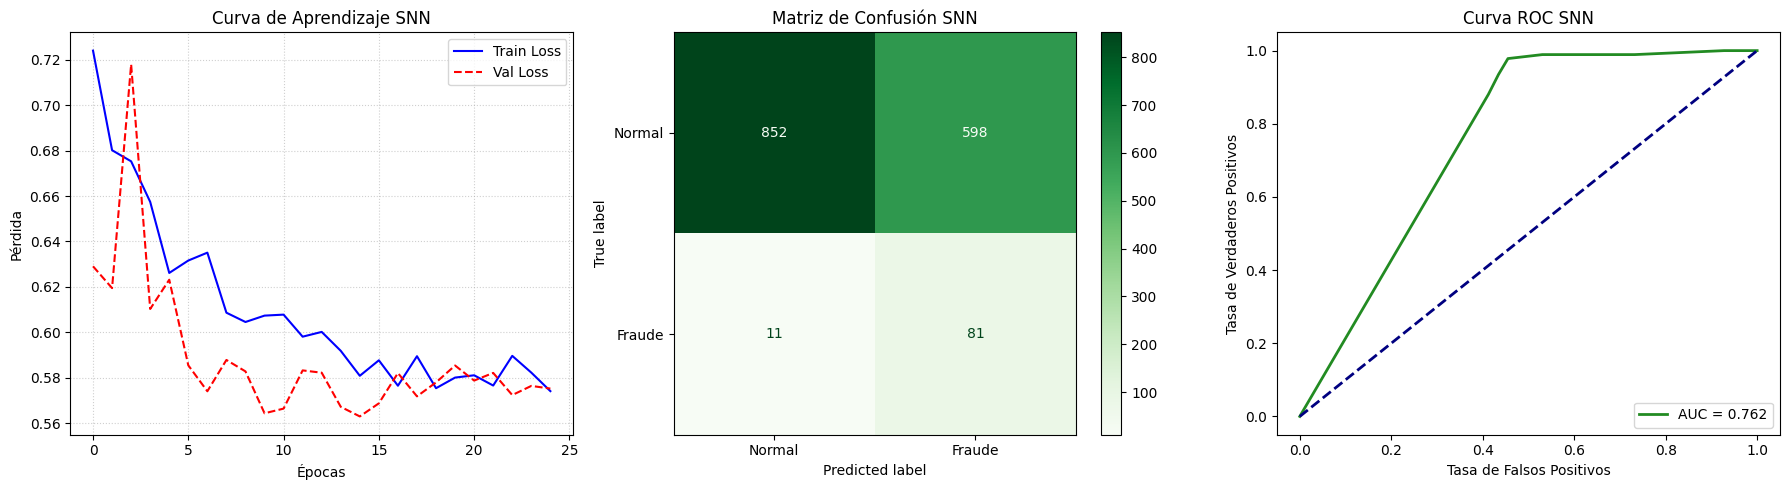

In [8]:
def evaluar_modelo_snn(modelo, dataloader, dispositivo):
    modelo.eval()
    y_true, y_pred, y_probs = [], [], []

    with torch.no_grad():
        for data, target in dataloader:
            data = data.to(dispositivo)
            spk_rec = modelo(data)
            spike_count = spk_rec.sum(dim=0)

            probs = torch.softmax(
            spike_count.double(), dim=1)[:, 1]

            # Aplicar el umbral seleccionado
            preds = (probs >= umbral).long()

            y_true.extend(target.numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

    print("--- Reporte de Clasificación Real (SNN) ---")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Fraude"]))

    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_probs)
    print(f"F1-Score (Fraude): {f1:.4f}")
    print(f"Área bajo la curva ROC (AUC): {roc_auc:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Curva de Pérdida
    axes[0].plot(history['train_loss'], label='Train Loss', color='blue')
    axes[0].plot(history['val_loss'], label='Val Loss', color='red', linestyle='--')
    axes[0].set_title('Curva de Aprendizaje SNN')
    axes[0].set_xlabel('Épocas')
    axes[0].set_ylabel('Pérdida')
    axes[0].legend()
    axes[0].grid(True, linestyle=':', alpha=0.6)

    # 2. Matriz
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraude'])
    disp.plot(ax=axes[1], cmap='Greens')
    axes[1].set_title('Matriz de Confusión SNN')

    # 3. ROC
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    axes[2].plot(fpr, tpr, color='forestgreen', lw=2, label=f'AUC = {roc_auc:.3f}')
    axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[2].set_title('Curva ROC SNN')
    axes[2].set_xlabel('Tasa de Falsos Positivos')
    axes[2].set_ylabel('Tasa de Verdaderos Positivos')
    axes[2].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

evaluar_modelo_snn(model, test_loader, device)
